# The v6 engine vs the v5 engine — the parallel split root on a common trajectory

## Goal

Measure the deployed parallel root — `parallel.search_v6` (connect6/parallel.py), the entry
the compiled engine serves in budget mode — against the sequential `vcf.search_v5` root it
extends, on the same forty-eight-decision-point recorded game as the v4/v5 notebooks
(loaded from `benchmarks/trajectory.json`). The change under test is the root of the
search only. In alpha-beta, a candidate searched later can be cut off early when another
candidate has already guaranteed a better result — the shared bounds (the "window") are
what collect those cutoffs. v5's root shares one `(MININT, MAXINT)` window across all root
candidates; v6 instead starts one independent worker job per candidate, each with its own
full window, and then selects the best-scoring candidate — the same move and score the
shared-window root returns at the same depth (the test suite's V6 Test 1 pins this on four
positions), because no subtree can use another candidate's results. The cost of the
split is exactly the cutoffs forgone: more nodes for the same answer. The deepening loop
works under `V6_NODE_BUDGET` (36,000 nodes, 3x v5's 12,000): the floor iteration almost
always fits, the next one usually exhausts the budget, and stage 1 — the forced-win
search, the first step of v5's three-step procedure (section 11.1) — still answers before
any tree is built.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tuning" / "default.json").is_file())
os.environ["WEIGHTS_FILE"] = str(ROOT / "tuning" / "winner.json")
os.environ["V6_JOBS"] = "1"
sys.path.insert(0, str(ROOT / "tuning"))

import harness
from connect6.parallel import search_v6
from connect6.search import search_alpha_beta_with_quiescence
from connect6.vcf import search_v5

print(f"weights pinned to {os.environ['WEIGHTS_FILE']} (the shipped champion)")
print("V6_JOBS=1: the split runs in-process; node counts are the pure tree price "
      "(the suite's V6 Test 4 pins the answer across one, three and pooled workers)")


weights pinned to /Users/e.butovka/Documents/MyProjects/Connect6Engine/tuning/winner.json (the shipped champion)
V6_JOBS=1: the split runs in-process; node counts are the pure tree price (the suite's V6 Test 4 pins the answer across one, three and pooled workers)


## The common trajectory

The recorded game is prepared data: `benchmarks/trajectory.json`, the pinned 48-ply
v4-vs-v4 self-play of section 10.2 — born and identity-checked in the v4 notebook, loaded
here without regenerating. Both engines are measured on the same game that measured v3
against v4 and the layer against the enhanced search.

In [2]:
import json

record = json.loads((ROOT / "benchmarks" / "trajectory.json").read_text())
history = record["history"]
assert record["outcome"] == {"winner": None, "plies": 48}
assert history[0] == "JJ" and len(history) == 49
print("common trajectory loaded: benchmarks/trajectory.json — 48 decision points, no win inside the cap")


rows = harness.analyze_history(history, [("v5", search_v5), ("v6", search_v6)], 3, jobs=12)
per_prefix = {}
for row in rows:
    per_prefix.setdefault(row.prefix, {})[row.name] = row
positions = sorted(per_prefix)
n = len(positions)

totals = {name: sum(per_prefix[p][name].nodes for p in positions) for name in ("v5", "v6")}
changes = sum(1 for p in positions if per_prefix[p]["v5"].move != per_prefix[p]["v6"].move)
flips = sum(1 for p in positions if (abs(per_prefix[p]["v5"].score) >= 20000) != (abs(per_prefix[p]["v6"].score) >= 20000))
divergences = [p for p in positions if per_prefix[p]["v5"].move != per_prefix[p]["v6"].move]
ones = [p for p in positions if per_prefix[p]["v6"].nodes == 1]
print(f"{'engine':6s} {'total nodes':>12s} {'mean/position':>13s} {'peak':>8s}")
for name in ("v5", "v6"):
    top = max(per_prefix[p][name].nodes for p in positions)
    at = max(positions, key=lambda p: per_prefix[p][name].nodes)
    print(f"{name:6s} {totals[name]:12,d} {totals[name] // n:13,d} {top:8,d} (prefix {at})")
print(f"move changes: {changes}/{n}   verdict-band flips: {flips}/{n}")
print(f"divergences: {divergences}")
print(f"one-node stage-1 answers (v6): {ones}")

common trajectory loaded: benchmarks/trajectory.json — 48 decision points, no win inside the cap


engine  total nodes mean/position     peak
v5        1,415,330        29,486  233,374 (prefix 34)
v6        3,288,692        68,514  259,118 (prefix 41)
move changes: 9/48   verdict-band flips: 0/48
divergences: [3, 19, 23, 25, 27, 29, 34, 37, 38]
one-node stage-1 answers (v6): [42, 44, 45, 46, 47]


In [3]:
EXPECTED_V6 = {
    "v5_nodes": 1415330,
    "v6_nodes": 3288692,
    "changes": 9,
    "flips": 0,
    "ones": [42, 44, 45, 46, 47],
    "v5_peak": 233374,
    "v6_peak": 259118,
    "divergences": [3, 19, 23, 25, 27, 29, 34, 37, 38],
}
assert totals["v5"] == EXPECTED_V6["v5_nodes"]
assert totals["v6"] == EXPECTED_V6["v6_nodes"]
assert changes == EXPECTED_V6["changes"]
assert flips == EXPECTED_V6["flips"]
assert ones == EXPECTED_V6["ones"]
assert max(per_prefix[p]["v5"].nodes for p in positions) == EXPECTED_V6["v5_peak"]
assert max(per_prefix[p]["v6"].nodes for p in positions) == EXPECTED_V6["v6_peak"]
assert divergences == EXPECTED_V6["divergences"]
print("the split root's answers and price reproduce exactly "
      "(nodes, changes, flips, one-node answers, peaks, divergences)")


the split root's answers and price reproduce exactly (nodes, changes, flips, one-node answers, peaks, divergences)


## The cost of a full window

Each split iteration spends more than the shared window — how much more varies
position to position, because the shared window's cutoffs depend on move ordering while
the split's jobs do not: across the forty-three decision points where the deployed roots
build a tree at all (the other five are one-node stage-1 answers), the floor-depth ratio
runs **1.00x to 26.2x, median 5.8x**, and 3.1x one depth further. The worst floor spike
is 258,821 nodes (prefix 41) against v5's entire 12,000-node budget — no budget multiple
makes the floor iteration universal, so the constant was chosen end-to-end instead: two
budgets were measured over this whole trajectory, 36,000 (3x v5) and 54,000 (4.5x). Both
diverge on 9 of 48 moves with **zero verdict-band flips**; the larger budget only spends
more (3.63x v5's nodes instead of 2.32x). The cheaper budget ships:
`V6_NODE_BUDGET = 36000`.


## The regression fixture

The position below is why V6 Test 1 has a fourth case. The split's collection loop once
broke early on a *losing* first candidate: for the minimizing side the running best score
starts at `MAXINT`, so a first candidate returning +20,000 — the mover's worst — tripped
the loop's terminal check and declared the whole position lost before the remaining
candidates were searched. The fixed loop breaks only on the mover's **own proven win**,
the exact condition the shared window's root cutoffs implement. The fixture replays the
game that caught it (the v1-vs-v6 ladder game, white's fifth move) and pins both
engines' answers; the cell also measures the two roots' node cost per depth on this position —
the floor iteration's 6.5x is the exhibit for the factor table above.


In [4]:
from connect6.defines import SearchStats
from connect6.parallel import _split_root
from connect6.protocol import move2msg
from connect6.search import search_alpha_beta_with_quiescence

BLUNDER_HISTORY = "JJ IIKK JKKI IKJL IJKL LMHJ KMLJ HIHK KJJI".split()
board, pre_move, color = harness.replay_history(BLUNDER_HISTORY)
print(f"the fixture: after {len(BLUNDER_HISTORY)} plies, white to move (the ladder game that caught the bug)")

fixture = {}
for name, search in (("v5", search_v5), ("v6", search_v6)):
    stats = SearchStats()
    result = search(board, color, 3, pre_move, stats)
    fixture[name] = (move2msg(result.move), result.score, stats.node_count, stats.depth_reached)
    print(f"{name}: {fixture[name][0]} score {fixture[name][1]} {fixture[name][2]:,} nodes (depth reached {fixture[name][3]})")

prices = {}
for depth in (3, 4):
    seq = SearchStats()
    search_alpha_beta_with_quiescence(board, color, depth, pre_move, seq)
    split = SearchStats()
    _split_root(board, color, depth, pre_move, split, None)
    prices[depth] = (seq.node_count, split.node_count)
    print(f"depth {depth}: shared window {seq.node_count:6,d} nodes, split {split.node_count:6,d} nodes "
          f"({split.node_count / max(seq.node_count, 1):.2f}x)")


the fixture: after 9 plies, white to move (the ladder game that caught the bug)


v5: MJHL score -402 20,583 nodes (depth reached 0)


v6: MJHL score -402 67,620 nodes (depth reached 4)


depth 3: shared window  1,951 nodes, split 12,657 nodes (6.49x)


depth 4: shared window 18,626 nodes, split 54,957 nodes (2.95x)


In [5]:
EXPECTED_FIXTURE = {
    "v5": ("MJHL", -402, 20583),
    "v6": ("MJHL", -402, 67620, 4),
    "price3": (1951, 12657),
    "price4": (18626, 54957),
}
assert fixture["v5"][:3] == EXPECTED_FIXTURE["v5"]
assert fixture["v6"] == EXPECTED_FIXTURE["v6"]
assert prices[3] == EXPECTED_FIXTURE["price3"]
assert prices[4] == EXPECTED_FIXTURE["price4"]
print("the fixture holds: both roots answer MJHL, and the split's price at depth 3 is 6.49x")


the fixture holds: both roots answer MJHL, and the split's price at depth 3 is 6.49x


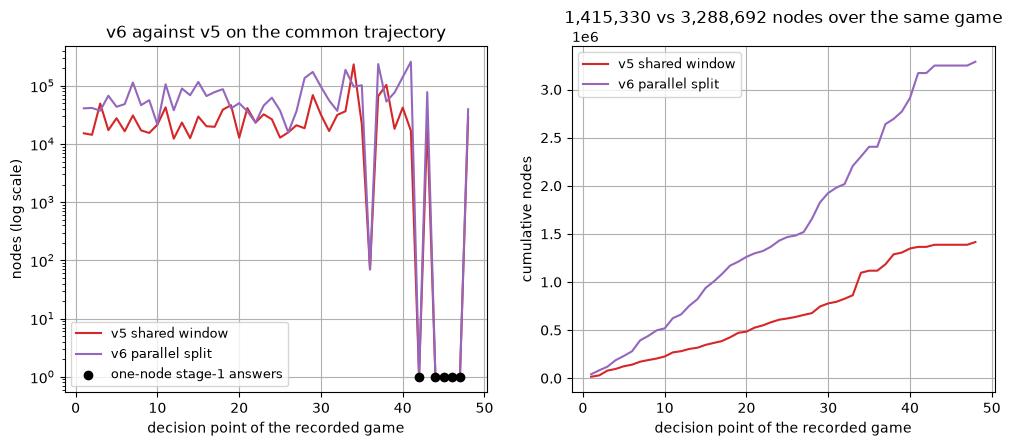

In [6]:
import matplotlib.pyplot as plt

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax.plot(positions, [per_prefix[p]["v5"].nodes for p in positions], color="tab:red", label="v5 shared window")
ax.plot(positions, [per_prefix[p]["v6"].nodes for p in positions], color="tab:purple", label="v6 parallel split")
ax.scatter(ones, [1] * len(ones), color="black", zorder=3, label="one-node stage-1 answers")
ax.set_yscale("log")
ax.set_xlabel("decision point of the recorded game")
ax.set_ylabel("nodes (log scale)")
ax.set_title("v6 against v5 on the common trajectory")
ax.grid(True)
ax.legend(fontsize=9)
ax2.plot(positions, [sum(per_prefix[q]["v5"].nodes for q in positions[:i + 1]) for i, p in enumerate(positions)], color="tab:red", label="v5 shared window")
ax2.plot(positions, [sum(per_prefix[q]["v6"].nodes for q in positions[:i + 1]) for i, p in enumerate(positions)], color="tab:purple", label="v6 parallel split")
ax2.set_xlabel("decision point of the recorded game")
ax2.set_ylabel("cumulative nodes")
ax2.set_title("1,415,330 vs 3,288,692 nodes over the same game")
ax2.grid(True)
ax2.legend(fontsize=9)
plt.show()


## Reading the results

- **The split keeps every verdict** — 39 of 48 moves identical, zero verdict-band flips,
  and the five one-node stage-1 answers reproduce at exactly one node: the forced-win
  layer runs before any tree is built, so proven wins cost the same in both roots. The
  nine divergences are all quiet (non-tactical) moves at budget boundaries, not tactics.
- **The cost is the full window** — 2.32x v5's nodes over the same game (3,288,692 vs
  1,415,330): every root candidate spends the nodes the missing cutoffs no longer save, and the
  per-iteration ratio swings 1.00x to 26.2x with the position's cuttability. The budget
  spends it where v5 spends its own: the floor iteration almost always fits, the next
  one usually ends the deepening.
- **The answers are the shared window's answers** — at equal depth the split returns the same
  best-scoring candidate the shared-window root proves (V6 Test 1, four positions including the
  regression fixture above), and the deployed answer is identical at one, three and
  pooled workers (V6 Test 4): the parallelism changes the cost of a move, never the
  move.
- The budget's own evidence — 36,000 vs 54,000 measured end-to-end, same divergences,
  zero flips both — is the choice's justification; the fixture's 6.49x floor cost is
  its exhibit. Full discussion: docs/EVALUATION.md, section 13.
